# Cine · Predicción de valoración y géneros a partir de la trama

**Entrega 2 | Desarrollo de soluciones analíticas**

¿Puede la trama en inglés anticipar la valoración histórica que recibiría una película y sugerir sus géneros? Este prototipo recibe solo una trama. Predice el valor de la columna **rating** en escala 1 a 10 y ordena tres géneros. La estimación apoya la evaluación inicial de historias por parte de una productora.


In [ ]:
import os
from pathlib import Path

# Limita el uso de hilos de BLAS en un kernel recién iniciado.
os.environ.setdefault('OPENBLAS_NUM_THREADS', '1')
os.environ.setdefault('OMP_NUM_THREADS', '1')

RAIZ = Path.cwd()
if RAIZ.name == 'notebooks' and (RAIZ.parent / 'cine').is_dir():
    RAIZ = RAIZ.parent
RUTA_DATOS = RAIZ / 'data' / 'dataTraining.zip'
DESTINO = RAIZ / 'artifacts'
TRACKING_URI = os.getenv('MLFLOW_TRACKING_URI', f'sqlite:///{RAIZ / "mlflow.db"}')
REGISTRAR_MLFLOW = True

## 1. Carga, control de calidad y particiones

Fuente: archivo etiquetado `dataTraining.zip` del curso MIAD ML and NLP. `plot` es la entrada. `rating` y `genres` son las dos salidas supervisadas. `year` se usa para describir la cobertura histórica. La base de competencia sin etiquetas se excluye del cálculo de métricas. La trama, normalizada para formar grupos, impide que dos copias exactas normalizadas queden en particiones distintas. La división aproximada es 60 % entrenamiento, 20 % validación y 20 % prueba. La prueba se usa tras seleccionar los candidatos.

In [ ]:
"""Entrenamiento y predicción a partir de una trama en inglés."""
import ast
import hashlib
import json
import os
from pathlib import Path
from urllib.request import urlretrieve

import joblib
import numpy as np
import pandas as pd
from sklearn.dummy import DummyRegressor
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, roc_auc_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.multiclass import OneVsRestClassifier
from sklearn.naive_bayes import ComplementNB
from sklearn.pipeline import FeatureUnion
from sklearn.preprocessing import MultiLabelBinarizer

SEMILLA = 42
VERSION_FUENTE = '9d748f56560253f3b3a7889b5b93c3ddb53c0f21'
URL = (
    f'https://raw.githubusercontent.com/albahnsen/MIAD_ML_and_NLP/{VERSION_FUENTE}'
    '/datasets/dataTraining.zip'
)
SHA256 = 'd217985a0aedcf17c6a4519582352bba8beb58d9c4186408b11950c4939f1ba6'
EJEMPLO = (
    'A young engineer discovers a mysterious radio signal from a missing research station. '
    'Together with a former detective, she follows the clues before a powerful corporation '
    'destroys the evidence.'
)


def cargar_datos(ruta):
    ruta = Path(ruta)
    if not ruta.exists():
        if ruta.name != 'dataTraining.zip':
            raise FileNotFoundError(ruta)
        ruta.parent.mkdir(parents=True, exist_ok=True)
        descarga = ruta.with_suffix('.part')
        urlretrieve(URL, descarga)
        if hashlib.sha256(descarga.read_bytes()).hexdigest() != SHA256:
            descarga.unlink()
            raise ValueError('La descarga no coincide con la versión del curso.')
        descarga.replace(ruta)
    huella = hashlib.sha256(ruta.read_bytes()).hexdigest()
    if ruta.name == 'dataTraining.zip' and huella != SHA256:
        raise ValueError('dataTraining.zip no coincide con la versión fijada del curso.')
    datos = pd.read_csv(ruta, index_col=0)
    columnas = {'plot', 'rating', 'genres', 'year'}
    if not columnas <= set(datos):
        raise ValueError(f'Columnas faltantes: {columnas - set(datos)}')
    if not datos.index.is_unique:
        raise ValueError('El primer campo del archivo debe contener ID únicos.')
    rating = pd.to_numeric(datos['rating'], errors='coerce')
    valido = (
        datos['plot'].fillna('').str.strip().ne('')
        & rating.between(1, 10)
        & datos['genres'].notna()
    )
    datos = datos.loc[valido].copy()
    datos['rating'] = rating.loc[valido]
    datos['genres'] = datos['genres'].map(ast.literal_eval)
    datos = datos.loc[datos['genres'].map(bool)].copy()
    return datos, huella


def particionar(datos):
    grupos = (datos['plot'].str.casefold()
              .str.replace(r'[^\w]+', ' ', regex=True).str.strip())
    externa = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEMILLA)
    desarrollo, prueba = next(externa.split(datos, groups=grupos))
    interna = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEMILLA + 1)
    entrenamiento, validacion = next(interna.split(
        datos.iloc[desarrollo], groups=grupos.iloc[desarrollo]
    ))
    partes = {
        'entrenamiento': datos.iloc[desarrollo[entrenamiento]],
        'validacion': datos.iloc[desarrollo[validacion]],
        'prueba': datos.iloc[prueba],
    }
    assert sum(map(len, partes.values())) == len(datos)
    conjuntos = [set(grupos.loc[parte.index]) for parte in partes.values()]
    assert all(not a & b for i, a in enumerate(conjuntos) for b in conjuntos[i + 1:])
    return partes

In [ ]:
datos, huella = cargar_datos(RUTA_DATOS)
partes = particionar(datos)
print('Huella SHA-256:', huella)
display(pd.DataFrame({'peliculas': {nombre: len(parte) for nombre, parte in partes.items()}}))
display(datos[['rating', 'year']].describe().round(3))
display(datos['genres'].explode().value_counts().rename('peliculas').to_frame())

Huella SHA-256: d217985a0aedcf17c6a4519582352bba8beb58d9c4186408b11950c4939f1ba6


,peliculas
entrenamiento,4736
validacion,1579
prueba,1580


,rating,year
count,7895.000,7895.000
mean,6.403,1989.726
std,1.078,22.661
min,1.200,1894.000
25%,5.800,1980.000
50%,6.500,1997.000
75%,7.200,2007.000
max,9.300,2015.000


,peliculas
genres,
Drama,3965
Comedy,3046
Thriller,2024
Romance,1892
Crime,1447
Action,1303
Adventure,1024
Horror,954
Mystery,759


## 2. Representación y comparación de modelos

El mismo TF-IDF combina palabras de 1 a 2 términos y caracteres de 4 a 6. Se aprende el vocabulario con `fit_transform()` en entrenamiento y se usa `transform()` en validación y prueba.

- **Valoración.** La referencia predice la mediana histórica. Ridge estima un valor continuo y prueba tres niveles de regularización. Se selecciona por MAE, expresado en puntos de rating. RMSE penaliza más los errores grandes, MSE expresa el error cuadrático medio y R² mide capacidad explicativa frente a la media observada.
- **Géneros.** Se compara la prevalencia histórica con regresión logística y ComplementNB en esquema uno contra el resto, y dos ensambles. Se selecciona por MCAUC, promedio del AUC por género con ejemplos positivos y negativos. Precisión@3 mide la fracción de las tres sugerencias que coincide con las etiquetas y recall@3 mide qué fracción de los géneros reales aparece entre esas sugerencias. Los puntajes de los ensambles se usan para ordenar etiquetas.

In [ ]:
def vectorizador():
    return FeatureUnion([
        ('palabras', TfidfVectorizer(
            ngram_range=(1, 2), min_df=2, max_df=0.95, max_features=100_000,
            strip_accents='unicode', sublinear_tf=True, dtype=np.float32,
        )),
        ('caracteres', TfidfVectorizer(
            analyzer='char', ngram_range=(4, 6), min_df=2, max_df=0.95,
            max_features=40_000, strip_accents='unicode', sublinear_tf=True,
            dtype=np.float32,
        )),
    ])


def metricas_rating(real, pred):
    mse = float(mean_squared_error(real, pred))
    return {
        'MAE': float(mean_absolute_error(real, pred)),
        'RMSE': float(np.sqrt(mse)),
        'MSE': mse,
        'R2': float(r2_score(real, pred)),
    }


def metricas_generos(real, scores, nombres, k=3):
    detalle = []
    for i, genero in enumerate(nombres):
        columna = real[:, i]
        auc = (float(roc_auc_score(columna, scores[:, i]))
               if len(np.unique(columna)) == 2 else np.nan)
        detalle.append({'genero': genero, 'AUC': auc, 'positivos': int(columna.sum())})
    detalle = pd.DataFrame(detalle)
    indices = np.argsort(-scores, axis=1, kind='stable')[:, :k]
    aciertos = np.take_along_axis(real, indices, axis=1).sum(axis=1)
    return {
        'MCAUC': float(detalle['AUC'].mean()),
        'precision_top3': float((aciertos / k).mean()),
        'recall_top3': float((aciertos / real.sum(axis=1)).mean()),
        'generos_con_AUC': int(detalle['AUC'].count()),
    }, detalle


def scores_generos(modelos, matriz):
    return sum(peso * modelo.predict_proba(matriz) for peso, modelo in modelos)


def ajustar_candidatos(partes):
    train, val = (partes[nombre] for nombre in ('entrenamiento', 'validacion'))
    tfidf = vectorizador()
    x_train = tfidf.fit_transform(train['plot'])
    x_val = tfidf.transform(val['plot'])

    etiquetas = MultiLabelBinarizer()
    y_train = etiquetas.fit_transform(train['genres'])
    y_val = codificar_generos(etiquetas, val)
    ratings = {
        'Mediana histórica': DummyRegressor(strategy='median').fit(x_train, train['rating'])
    }
    parametros = {
        'Mediana histórica': {'strategy': 'median', 'entrada': 'constante'},
        'Frecuencia histórica': {'strategy': 'prevalencia', 'entrada': 'constante'},
        'Regresión logística': {'C': 1.0, 'solver': 'liblinear'},
        'ComplementNB': {'alpha': 0.03},
        'Ensamble 90/10': {'C': 1.0, 'alpha': 0.03, 'peso_NB': 0.10},
        'Ensamble 97/03': {'C': 1.0, 'alpha': 0.03, 'peso_NB': 0.03},
    }
    for alpha in (0.1, 1.0, 10.0):
        nombre = f'Ridge alpha={alpha:g}'
        ratings[nombre] = Ridge(alpha=alpha, solver='lsqr').fit(x_train, train['rating'])
        parametros[nombre] = {'alpha': alpha, 'solver': 'lsqr'}
    lr = OneVsRestClassifier(
        LogisticRegression(C=1.0, solver='liblinear', max_iter=1000, random_state=SEMILLA)
    ).fit(x_train, y_train)
    nb = OneVsRestClassifier(ComplementNB(alpha=0.03)).fit(x_train, y_train)
    generos = {
        'Regresión logística': [(1.0, lr)],
        'ComplementNB': [(1.0, nb)],
        'Ensamble 90/10': [(0.90, lr), (0.10, nb)],
        'Ensamble 97/03': [(0.97, lr), (0.03, nb)],
    }
    prevalencia = y_train.mean(axis=0)
    scores_val = {'Frecuencia histórica': np.tile(prevalencia, (len(val), 1))}
    scores_val.update({n: scores_generos(m, x_val) for n, m in generos.items()})
    val_generos = pd.DataFrame([
        {'modelo': n, **metricas_generos(y_val, p, etiquetas.classes_)[0]}
        for n, p in scores_val.items()
    ]).sort_values('MCAUC', ascending=False, kind='stable', ignore_index=True)
    val_rating = pd.DataFrame([
        {'modelo': n, **metricas_rating(val['rating'], np.clip(m.predict(x_val), 1, 10))}
        for n, m in ratings.items()
    ]).sort_values('MAE', kind='stable', ignore_index=True)

    # Selección exclusivamente con validación.
    mejor_rating = val_rating.iloc[0]['modelo']
    mejor_generos = val_generos.loc[
        val_generos['modelo'].ne('Frecuencia histórica'), 'modelo'
    ].iloc[0]
    paquete = {
        'tfidf': tfidf, 'rating': ratings[mejor_rating], 'generos': generos[mejor_generos],
        'etiquetas': etiquetas, 'nombres': {'rating': mejor_rating, 'generos': mejor_generos},
    }
    return paquete, val_rating, val_generos, parametros, ratings['Mediana histórica'], prevalencia


def codificar_generos(etiquetas, parte):
    desconocidos = set(parte['genres'].explode()) - set(etiquetas.classes_)
    if desconocidos:
        raise ValueError(f'Géneros ausentes en entrenamiento: {sorted(desconocidos)}')
    return etiquetas.transform(parte['genres'])


def evaluar_prueba(paquete, prueba, mediana, prevalencia):
    x_test = paquete['tfidf'].transform(prueba['plot'])
    y_test = codificar_generos(paquete['etiquetas'], prueba)
    rating = np.clip(paquete['rating'].predict(x_test), 1, 10)
    ratings = [('Mediana histórica', mediana.predict(x_test))]
    if paquete['nombres']['rating'] != 'Mediana histórica':
        ratings.append((paquete['nombres']['rating'], rating))
    prueba_rating = pd.DataFrame([
        {'modelo': nombre, **metricas_rating(prueba['rating'], pred)}
        for nombre, pred in ratings
    ])
    base = np.tile(prevalencia, (len(prueba), 1))
    m_base, _ = metricas_generos(y_test, base, paquete['etiquetas'].classes_)
    scores = scores_generos(paquete['generos'], x_test)
    m_modelo, detalle = metricas_generos(y_test, scores, paquete['etiquetas'].classes_)
    prueba_generos = pd.DataFrame([
        {'modelo': 'Frecuencia histórica', **m_base},
        {'modelo': paquete['nombres']['generos'], **m_modelo},
    ])
    errores = pd.DataFrame({
        'real': prueba['rating'], 'predicho': rating,
        'error_absoluto': (prueba['rating'] - rating).abs(),
    })
    return prueba_rating, prueba_generos, detalle, errores

In [ ]:
paquete, val_rating, val_generos, parametros, mediana, prevalencia = ajustar_candidatos(partes)
print('Valoración · validación')
display(val_rating.round(4))
print('Géneros · validación')
display(val_generos.round(4))
print('Selección:', paquete['nombres'])

Valoración · validación
Géneros · validación
Selección: {'rating': 'Ridge alpha=10', 'generos': 'Ensamble 90/10'}


,modelo,MAE,RMSE,MSE,R2
0,Ridge alpha=10,0.7542,0.9887,0.9775,0.1376
1,Ridge alpha=1,0.7713,1.0064,1.0128,0.1066
2,Ridge alpha=0.1,0.8167,1.0588,1.1210,0.0111
3,Mediana histórica,0.8168,1.0669,1.1382,-0.0041


,modelo,MCAUC,precision_top3,recall_top3,generos_con_AUC
0,Ensamble 90/10,0.8851,0.5590,0.6676,23
1,Ensamble 97/03,0.8850,0.5493,0.6561,23
2,Regresión logística,0.8843,0.5440,0.6515,23
3,ComplementNB,0.8621,0.5765,0.6840,23
4,Frecuencia histórica,0.5000,0.3804,0.4692,23


## 3. Evaluación en prueba reservada

Se compara la selección de validación con la referencia histórica, usando las mismas películas para cada comparación. También se revisa el desempeño por género y por nivel de valoración.

In [ ]:
prueba_rating, prueba_generos, auc_por_genero, errores = evaluar_prueba(
    paquete, partes['prueba'], mediana, prevalencia
)
display(prueba_rating.round(4))
display(prueba_generos.round(4))
display(auc_por_genero.sort_values('AUC').round(4))
tramos = pd.cut(errores['real'], bins=[1, 5, 7, 10], include_lowest=True,
                labels=['1 a 5', 'más de 5 a 7', 'más de 7 a 10'])
display(errores.groupby(tramos, observed=True).agg(
    peliculas=('real', 'size'), rating_real=('real', 'mean'),
    rating_estimado=('predicho', 'mean'), MAE=('error_absoluto', 'mean')
).round(4))

,modelo,MAE,RMSE,MSE,R2
0,Mediana histórica,0.8287,1.0716,1.1483,-0.0082
1,Ridge alpha=10,0.7628,0.9873,0.9747,0.1443


,modelo,MCAUC,precision_top3,recall_top3,generos_con_AUC
0,Frecuencia histórica,0.500,0.3861,0.4672,24
1,Ensamble 90/10,0.882,0.5601,0.6590,24


,genero,AUC,positivos
7,Drama,0.7745,797
4,Comedy,0.8155,619
19,Short,0.8226,14
16,News,0.8284,1
3,Biography,0.8285,85
14,Musical,0.8416,57
17,Romance,0.8423,351
21,Thriller,0.8426,414
15,Mystery,0.8641,147
9,Fantasy,0.8687,128


,peliculas,rating_real,rating_estimado,MAE
real,,,,
1 a 5,160,4.2550,6.2059,1.9509
más de 5 a 7,950,6.2016,6.3660,0.4396
más de 7 a 10,470,7.5434,6.5321,1.0118


## 4. Artefactos, figuras e inferencia de una trama

Se exportan el paquete de inferencia, la información descriptiva del tablero, las tablas de evaluación, la asignación de particiones y dos figuras. El ejemplo de la maqueta se evalúa con los modelos entrenados.

In [ ]:
def contexto(datos):
    bordes = [1, 3, 5, 6, 7, 8, 9, 10]
    intervalos = pd.cut(datos['rating'], bordes, include_lowest=True)
    frec = datos['genres'].explode().value_counts()
    return {
        'peliculas': len(datos), 'rating_medio': float(datos['rating'].mean()),
        'anio_min': int(datos['year'].min()), 'anio_max': int(datos['year'].max()),
        'n_generos': len(frec),
        'ratings': [
            {'label': f'{lo} a {hi}', 'count': int(n)}
            for lo, hi, n in zip(bordes, bordes[1:], intervalos.value_counts(sort=False))
        ],
        'generos': [{'label': str(g), 'count': int(n)} for g, n in frec.items()],
    }


def guardar(paquete, datos, partes, tablas, huella, destino):
    destino = Path(destino)
    destino.mkdir(parents=True, exist_ok=True)
    paquete['sha256_datos'] = huella
    joblib.dump(paquete, destino / 'modelos.joblib', compress=3)
    (destino / 'contexto.json').write_text(
        json.dumps(contexto(datos), ensure_ascii=False, indent=2), encoding='utf-8'
    )
    for nombre, tabla in tablas.items():
        tabla.to_csv(destino / f'{nombre}.csv', index=nombre == 'errores_rating')
    pd.concat([
        pd.DataFrame({'id': parte.index, 'particion': nombre})
        for nombre, parte in partes.items()
    ]).to_csv(destino / 'particiones.csv', index=False)


def predecir(paquete, trama):
    if not isinstance(trama, str) or not 40 <= len(trama.strip()) <= 10_000:
        raise ValueError('Ingrese una trama en inglés de 40 a 10.000 caracteres.')
    matriz = paquete['tfidf'].transform([trama.strip()])
    if not matriz.nnz:
        raise ValueError('La trama no contiene términos reconocidos por el modelo.')
    score = scores_generos(paquete['generos'], matriz)[0]
    orden = np.argsort(-score, kind='stable')[:3]
    nombres = paquete['etiquetas'].classes_
    return {
        'rating': round(float(np.clip(paquete['rating'].predict(matriz)[0], 1, 10)), 2),
        'generos': [{'genero': str(nombres[i]), 'score': round(float(score[i]), 4)}
                    for i in orden],
    }

In [ ]:
"""Evidencia de evaluación y versionamiento de los modelos."""
import subprocess
from tempfile import TemporaryDirectory

import matplotlib.pyplot as plt



def graficas(val_rating, val_generos, prueba_rating, errores, destino):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout='constrained')
    for ax, tabla, campo, titulo in (
        (axes[0], val_rating, 'MAE', 'Valoración · menor MAE es mejor'),
        (axes[1], val_generos, 'MCAUC', 'Géneros · mayor MCAUC es mejor'),
    ):
        barras = ax.barh(tabla['modelo'], tabla[campo], color='#5146a8')
        ax.invert_yaxis()
        ax.set_xlim(0, 1.08 * max(tabla[campo]))
        ax.bar_label(barras, fmt='%.3f', padding=3)
        ax.set_title(titulo)
        ax.spines[['right', 'top']].set_visible(False)
    fig.savefig(destino / 'comparacion_validacion.png', dpi=160)

    fig2, (a, b) = plt.subplots(1, 2, figsize=(10, 4), layout='constrained')
    a.scatter(errores['real'], errores['predicho'], color='#5146a8', alpha=.25, s=13)
    a.plot([1, 10], [1, 10], '--', color='#606870', lw=1)
    a.set(xlim=(1, 10), ylim=(1, 10), xlabel='Rating observado',
          ylabel='Rating estimado', title='Prueba · observado frente a estimado')
    barras = b.barh(prueba_rating['modelo'], prueba_rating['MAE'], color=['#738294', '#5146a8'][:len(prueba_rating)])
    b.invert_yaxis()
    b.set_xlim(0, 1.12 * prueba_rating['MAE'].max())
    b.bar_label(barras, fmt='%.3f', padding=3)
    b.set(xlabel='Error en puntos sobre 10', title='Prueba · MAE frente a la referencia')
    fig2.savefig(destino / 'diagnostico_rating.png', dpi=160)
    return fig, fig2

A young engineer discovers a mysterious radio signal from a missing research station. Together with a former detective, she follows the clues before a powerful corporation destroys the evidence.
{
  "rating": 5.71,
  "generos": [
    {
      "genero": "Thriller",
      "score": 0.6676
    },
    {
      "genero": "Sci-Fi",
      "score": 0.4162
    },
    {
      "genero": "Mystery",
      "score": 0.3821
    }
  ]
}


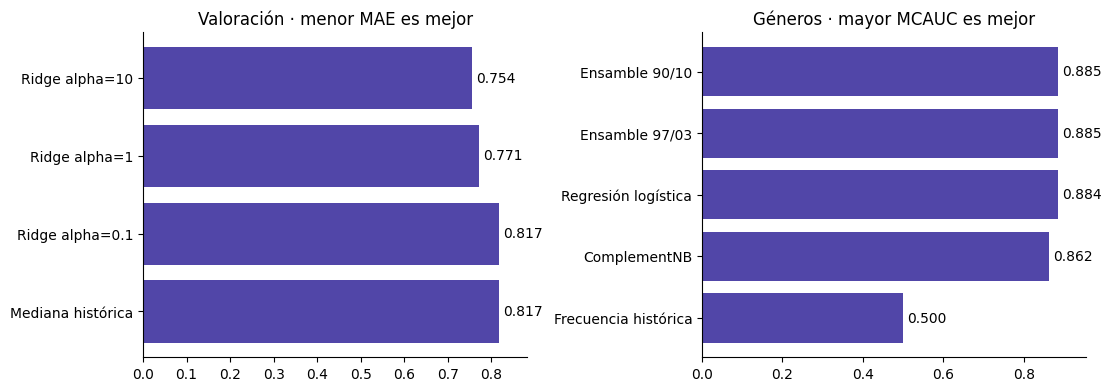

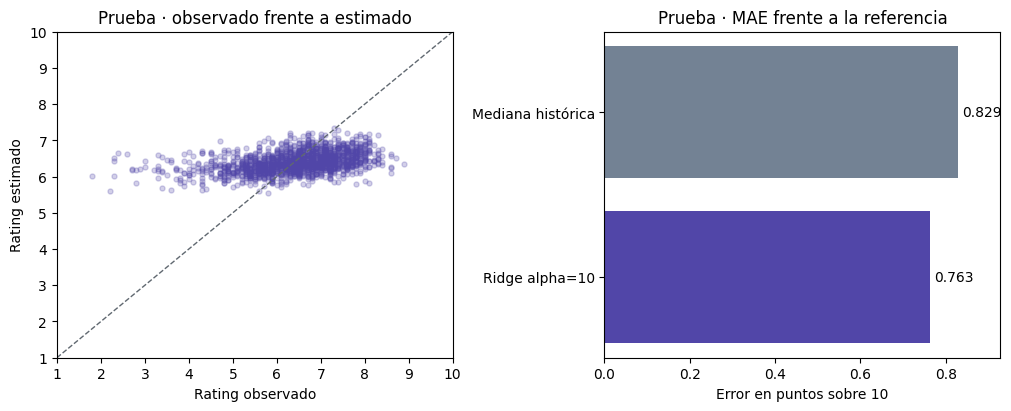

In [ ]:
tablas = dict(validacion_rating=val_rating, validacion_generos=val_generos,
              prueba_rating=prueba_rating, prueba_generos=prueba_generos,
              auc_por_genero=auc_por_genero, errores_rating=errores)
guardar(paquete, datos, partes, tablas, huella, DESTINO)
_ = graficas(val_rating, val_generos, prueba_rating, errores, DESTINO)
plt.show()
print(EJEMPLO)
print(json.dumps(predecir(paquete, EJEMPLO), indent=2, ensure_ascii=False))

## 5. MLflow Tracking y Model Registry

Cada candidato genera una corrida con parámetros, resultados de validación y trazabilidad del conjunto de datos. Se registra la prueba únicamente para el candidato elegido y su referencia. Los modelos elegidos se versionan como `cine-rating` y `cine-generos`, con firma, ejemplo de entrada y dependencias. Con `REGISTRAR_MLFLOW = False` se pueden generar los artefactos de inferencia sin acceso al servidor.

In [ ]:
def revision_git():
    try:
        commit = subprocess.check_output(
            ['git', 'rev-parse', 'HEAD'], text=True, stderr=subprocess.DEVNULL
        ).strip()
        cambios = subprocess.check_output(['git', 'status', '--porcelain'], text=True)
        return commit, bool(cambios.strip())
    except (OSError, subprocess.CalledProcessError):
        return 'sin_commit_local', False


# MLflow carga este código y el artefacto de cada tarea como un modelo portable.
CODIGO_MLFLOW = """
import joblib
import mlflow
import numpy as np
import pandas as pd

class Predictor(mlflow.pyfunc.PythonModel):
    def load_context(self, context):
        self.vectorizador, self.estimador, self.nombres = joblib.load(context.artifacts['pesos'])

    def predict(self, context, model_input: pd.DataFrame) -> pd.DataFrame:
        x = self.vectorizador.transform(model_input['plot'])
        if self.nombres is None:
            return pd.DataFrame({'rating': np.clip(self.estimador.predict(x), 1, 10)})
        scores = sum(peso * modelo.predict_proba(x) for peso, modelo in self.estimador)
        return pd.DataFrame(scores, columns=self.nombres)

mlflow.models.set_model(Predictor())
""".strip()


def registrar_modelo(mlflow, tarea, paquete, destino):
    from importlib.metadata import version

    entrada = pd.DataFrame({'plot': [EJEMPLO]})
    x = paquete['tfidf'].transform(entrada['plot'])
    modelo = paquete[tarea]
    if tarea == 'rating':
        nombres = None
        salida = pd.DataFrame({'rating': np.clip(modelo.predict(x), 1, 10)})
    else:
        nombres = list(paquete['etiquetas'].classes_)
        scores = sum(peso * estimador.predict_proba(x) for peso, estimador in modelo)
        salida = pd.DataFrame(scores, columns=nombres)

    with TemporaryDirectory(dir=destino) as temporal:
        archivo = Path(temporal) / 'predictor.py'
        archivo.write_text(CODIGO_MLFLOW, encoding='utf-8')
        pesos = Path(temporal) / 'pesos.joblib'
        joblib.dump((paquete['tfidf'], modelo, nombres), pesos, compress=3)
        info = mlflow.pyfunc.log_model(
            name=tarea, python_model=str(archivo), artifacts={'pesos': str(pesos)},
            signature=mlflow.models.infer_signature(entrada, salida),
            input_example=entrada, registered_model_name=f'cine-{tarea}',
            pip_requirements=[
                f'{p}=={version(p)}' for p in
                ('mlflow', 'numpy', 'pandas', 'scikit-learn', 'scipy', 'joblib')
            ],
        )
    return info.model_uri


def registrar(tracking_uri, paquete, tablas, parametros, partes, huella, destino):
    import mlflow

    mlflow.set_tracking_uri(tracking_uri)
    commit, cambios = revision_git()
    registros = []
    for tarea in ('rating', 'generos'):
        experimento = f'cine-trama-{tarea}'
        mlflow.set_experiment(experimento)
        prueba = tablas[f'prueba_{tarea}'].set_index('modelo')
        for fila in tablas[f'validacion_{tarea}'].to_dict('records'):
            nombre = fila.pop('modelo')
            elegido = nombre == paquete['nombres'][tarea]
            with mlflow.start_run(run_name=nombre) as run:
                mlflow.set_tags({
                    'git_commit': commit, 'git_dirty': str(cambios).lower(),
                    'dataset_sha256': huella, 'dataset_commit_referencia': VERSION_FUENTE,
                    'seleccionado': str(elegido).lower(),
                })
                mlflow.log_params({
                    'semilla_externa': SEMILLA, 'semilla_interna': SEMILLA + 1,
                    'input': 'plot', 'particion': 'agrupada_60_20_20',
                    **{f'n_{n}': len(p) for n, p in partes.items()},
                    **parametros[nombre],
                })
                if parametros[nombre].get('entrada') != 'constante':
                    mlflow.log_params({
                        'word_ngrams': '1-2', 'char_ngrams': '4-6', 'min_df': 2,
                        'max_df': .95, 'max_words': 100_000, 'max_chars': 40_000,
                        'sublinear_tf': True, 'strip_accents': 'unicode',
                    })
                mlflow.log_metrics({f'val_{k}': float(v) for k, v in fila.items()})
                if nombre in prueba.index:
                    mlflow.log_metrics({
                        f'test_{k}': float(v) for k, v in prueba.loc[nombre].items()
                    })
                uri = ''
                if elegido:
                    for fichero in ('particiones.csv', 'comparacion_validacion.png',
                                    f'validacion_{tarea}.csv', f'prueba_{tarea}.csv'):
                        mlflow.log_artifact(str(destino / fichero))
                    evidencia = ('diagnostico_rating.png' if tarea == 'rating'
                                 else 'auc_por_genero.csv')
                    mlflow.log_artifact(str(destino / evidencia))
                    uri = registrar_modelo(mlflow, tarea, paquete, destino)
                registros.append({'experimento': experimento, 'modelo': nombre,
                                  'run_id': run.info.run_id, 'model_uri': uri})
    return pd.DataFrame(registros)

In [ ]:
if REGISTRAR_MLFLOW:
    registros = registrar(TRACKING_URI, paquete, tablas, parametros, partes, huella, DESTINO)
    registros.to_csv(DESTINO / 'mlflow_runs.csv', index=False)
    display(registros)

2026/11/08 16:32:47 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/08 16:32:47 INFO mlflow.store.db.utils: Updating database tables
2026/11/08 16:32:48 INFO mlflow.tracking.fluent: Experiment with name 'cine-trama-rating' does not exist. Creating a new experiment.
2026/11/08 16:32:50 INFO mlflow.pyfunc: Validating input example against model signature
Successfully registered model 'cine-rating'.
Created version '1' of model 'cine-rating'.
2026/11/08 16:32:51 INFO mlflow.tracking.fluent: Experiment with name 'cine-trama-generos' does not exist. Creating a new experiment.
2026/11/08 16:32:57 INFO mlflow.pyfunc: Validating input example against model signature
Successfully registered model 'cine-generos'.
Created version '1' of model 'cine-generos'.


,experimento,modelo,run_id,model_uri
0,cine-trama-rating,Ridge alpha=10,abf11c4d6423445997657b7c0afea86b,models:/m-e99eafd2c52746c989e28271fbb2c6ac
1,cine-trama-rating,Ridge alpha=1,2412dd16c19a4bd49458bdf5ad27bbf1,
2,cine-trama-rating,Ridge alpha=0.1,34c4c67e34624159b369f0ececbed558,
3,cine-trama-rating,Mediana histórica,2bd7c87e9bec4d99a33205ad8691e035,
4,cine-trama-generos,Ensamble 90/10,68040175c32842d58f99eb073faf7fa2,models:/m-95a4bcaa2a7e4ac0845cf081a0aacec8
5,cine-trama-generos,Ensamble 97/03,b89435aa6c684ec0bb67adc8554d7c9e,
6,cine-trama-generos,Regresión logística,eac169f13a464d87b9205a1f8e531cfe,
7,cine-trama-generos,ComplementNB,09565cf8fc364a6696087e5f04567e14,
8,cine-trama-generos,Frecuencia histórica,8911d539a5bf41459b848359d18445e8,


## 6. Conclusión 
En la ejecución con la base original, Ridge con α = 10 pasó de un MAE de referencia de **0,829** a **0,763 puntos** en prueba, una reducción relativa de **7,9 %**. El R² fue **0,144**. En películas con rating de hasta 5, el error medio fue **1,951** y la estimación media fue **6,206** frente a **4,255** observados. La valoración aporta una referencia inicial, con especial cautela en los extremos y para decisiones de inversión.

El ensamble logístico/ComplementNB 90/10 logró **0,882 de MCAUC**, **56,0 % de precisión@3** y **65,9 % de recall@3** en prueba. En validación, ComplementNB solo obtuvo mayor precisión@3 (57,7 % frente a 55,9 %), mientras el ensamble obtuvo mayor MCAUC (0,8851 frente a 0,8621). Se conservó el criterio de ranking global definido para esta entrega. *News* quedó sin positivos en validación y tuvo un positivo en prueba. Su AUC individual requiere más datos para interpretarse.

La evaluación es retrospectiva sobre sinopsis de películas estrenadas entre 1894 y 2015. El modelo debe validarse con sinopsis de proyectos nuevos para conocer su desempeño en el proceso editorial de una productora.